#                            AI MINI PROJECT (GROUP - 17)
###              PREDICTING TEMPERATURE SWINGS WITH HELP OF 2020-2024 DATASET 

##### Downloading Pandas and matplotlib

In [2]:
%pip install pandas
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 578.2 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/9.3 MB 578.2 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/9.3 MB 578.2 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/9.3 MB 578.2 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/9.3 MB 578.2 kB/s eta 0:00:16
   --- ------------------------------------ 0.8/9.3 MB 364.4 kB/s eta 0:00:24
   --- ------------------------------------ 0.8/9.3 MB 36


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Download scikit-learn

In [4]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   --------------- ------------------------ 3.1/8.2 MB 16.1 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.2 MB 16.4 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 15.7 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   --- ------------------------------------ 3.4/36.6 MB 17.2 MB/s eta 0:00:02
   ------- -------------------------------- 6.8/36.6 MB 16.2 MB/s eta 0:00:02
   ----------- ---------------------------- 10.2/36.6 MB 16.4 MB/s eta 0:00:02
   --------------- ------------------------ 13.9/36.6 MB 16.4 MB/s eta 0:00:02
   ------------------ --------------------- 17.3/36.6 MB 16.4 MB/s eta 0:00:02
   ---------------------- ----------------- 20.7/36.6 MB 16.4 MB/s eta 0:00:01
   ------------------------- -------------- 23.1/36.6 MB 16.4 MB/s eta 0:00:01
   ---------------------------- ----------- 26.2/36.6 MB 15.5 MB/s eta 0:00:01
   


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.1. Import Libraries

In [5]:
import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display graphs inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


## Read Dataset

In [8]:
# https://www.kaggle.com/datasets/atifmasih/climate-change-dataset2020-2024/versions/1?hl=en-IN
df = pd.read_csv('climate_change_dataset.csv')
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (53, 20)


,Year,Month,Avg_Temp (°C),Max_Temp (°C),Min_Temp (°C),Precipitation (mm),Humidity (%),Wind_Speed (m/s),Solar_Irradiance (W/m²),Cloud_Cover (%),CO2_Concentration (ppm),Latitude,Longitude,Altitude (m),Proximity_to_Water (km),Urbanization_Index,Vegetation_Index,ENSO_Index,Particulate_Matter (µg/m³),Sea_Surface_Temp (°C)
0,NaN,1.0,-3.460516,33.056918907353285,NaN,184.89969755743786,89.62081302618182,9.742885739415993,NaN,58.530797670209076,NaN,40.7128,NaN,10.0,15.0,NaN,0.04423782887418304,0.6336943092843479,33.43707805480527,18.545360112309588
1,2020.0,2.0,NaN,25.901916083791665,3.1739745975583844,2.957244192049635,95.17102000342224,10.64824600272703,252.3136442294677,32.85666516634471,419.595924,40.7128,-74.006,10.0,15.0,99999.000000,0.6128400325468267,NaN,24.504783135571934,15.909586979280654
2,2020.0,3.0,7.869842,18.63424149980029,10.42485208665568,NaN,NaN,NaN,247.39139984511084,29.380233637986674,416.650458,40.7128,-74.006,10.0,15.0,0.341732,0.4665653848003175,-0.4280583600093959,32.3274997743319,21.281093622177334
3,NaN,4.0,-0.049863,13.030562376875533,-9.196433418151315,102.4544605414934,Unknown,0.898697634212508,143.26161801322706,17.496855610388273,418.922808,40.7128,-74.006,10.0,15.0,0.896383,0.030465932726280065,-0.5707078659552114,20.496275820817043,NaN
4,2020.0,5.0,19.895067,35.88212887551623,20.067999652410148,185.72922332959365,73.99994640624561,13.128301152215258,169.5494376964624,2.1937104861995405,401.896588,40.7128,-74.006,10.0,99999.0,0.076173,NaN,-0.2861494705734404,22.64905691725084,15.502968235198333


## Understand the Dataset

In [9]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (53, 20)

Column names:
['Year', 'Month', 'Avg_Temp (°C)', 'Max_Temp (°C)', 'Min_Temp (°C)', 'Precipitation (mm)', 'Humidity (%)', 'Wind_Speed (m/s)', 'Solar_Irradiance (W/m²)', 'Cloud_Cover (%)', 'CO2_Concentration (ppm)', 'Latitude', 'Longitude', 'Altitude (m)', 'Proximity_to_Water (km)', 'Urbanization_Index', 'Vegetation_Index', 'ENSO_Index', 'Particulate_Matter (µg/m³)', 'Sea_Surface_Temp (°C)']

First five rows:


,Year,Month,Avg_Temp (°C),Max_Temp (°C),Min_Temp (°C),Precipitation (mm),Humidity (%),Wind_Speed (m/s),Solar_Irradiance (W/m²),Cloud_Cover (%),CO2_Concentration (ppm),Latitude,Longitude,Altitude (m),Proximity_to_Water (km),Urbanization_Index,Vegetation_Index,ENSO_Index,Particulate_Matter (µg/m³),Sea_Surface_Temp (°C)
0,NaN,1.0,-3.460516,33.056918907353285,NaN,184.89969755743786,89.62081302618182,9.742885739415993,NaN,58.530797670209076,NaN,40.7128,NaN,10.0,15.0,NaN,0.04423782887418304,0.6336943092843479,33.43707805480527,18.545360112309588
1,2020.0,2.0,NaN,25.901916083791665,3.1739745975583844,2.957244192049635,95.17102000342224,10.64824600272703,252.3136442294677,32.85666516634471,419.595924,40.7128,-74.006,10.0,15.0,99999.000000,0.6128400325468267,NaN,24.504783135571934,15.909586979280654
2,2020.0,3.0,7.869842,18.63424149980029,10.42485208665568,NaN,NaN,NaN,247.39139984511084,29.380233637986674,416.650458,40.7128,-74.006,10.0,15.0,0.341732,0.4665653848003175,-0.4280583600093959,32.3274997743319,21.281093622177334
3,NaN,4.0,-0.049863,13.030562376875533,-9.196433418151315,102.4544605414934,Unknown,0.898697634212508,143.26161801322706,17.496855610388273,418.922808,40.7128,-74.006,10.0,15.0,0.896383,0.030465932726280065,-0.5707078659552114,20.496275820817043,NaN
4,2020.0,5.0,19.895067,35.88212887551623,20.067999652410148,185.72922332959365,73.99994640624561,13.128301152215258,169.5494376964624,2.1937104861995405,401.896588,40.7128,-74.006,10.0,99999.0,0.076173,NaN,-0.2861494705734404,22.64905691725084,15.502968235198333



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Year                        48 non-null     str    
 1   Month                       48 non-null     str    
 2   Avg_Temp (°C)               46 non-null     float64
 3   Max_Temp (°C)               46 non-null     str    
 4   Min_Temp (°C)               45 non-null     str    
 5   Precipitation (mm)          49 non-null     str    
 6   Humidity (%)                45 non-null     str    
 7   Wind_Speed (m/s)            51 non-null     str    
 8   Solar_Irradiance (W/m²)     48 non-null     str    
 9   Cloud_Cover (%)             49 non-null     str    
 10  CO2_Concentration (ppm)     47 non-null     float64
 11  Latitude                    47 non-null     str    
 12  Longitude                   50 non-null     str    
 13  Altitude

,Avg_Temp (°C),CO2_Concentration (ppm),Urbanization_Index
count,46.000000,47.000000,50.000000
mean,13.018699,423.475586,4000.477221
std,11.557213,13.820859,19794.561777
min,-4.965473,400.351530,0.016689
25%,4.682635,412.434113,0.270233
50%,10.422940,425.653185,0.566592
75%,22.992501,436.739556,0.853385
max,34.282303,444.483466,99999.000000


# Explore the Data with Graphs

Numeric columns: ['Avg_Temp (°C)', 'CO2_Concentration (ppm)', 'Urbanization_Index']


AttributeError: module 'matplotlib.pyplot' has no attribute 'ylable'

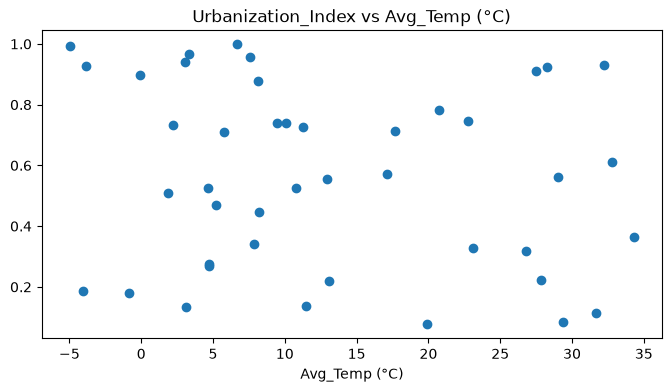

In [13]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

# Change this to a numeric column in your dataset

x_column = numeric_columns[0]
y_column = numeric_columns[2]

plt.figure(figsize=(8, 4))

plt.scatter(df[x_column], df[y_column])

plt.title(f"{y_column} vs {x_column}")
plt.xlabel(x_column)
plt.ylable(y_column)

plt.grid(alpha = 0.5)
plt.show






